calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object m

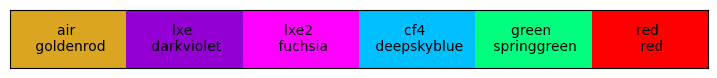

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang
import time

import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel.OpticsDataLoader import *
import PDEModel.MathEquations as ME
import PDEModel.PhotonInfo as PI
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

import FittingTools.PDE_fittingTools as SS
from FittingTools import FittingFunctions as FFS

from scipy.interpolate import interp1d

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

---
### Loading low res data

In [2]:
print("---- Low Res Data ----")
file_path = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_LowRes_stat_error_only_April18.csv")
# file_path = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_LowRes_stat_error_only_June2024.csv") # 1V data is higher in this dataset?
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
print("Voltages:", df['Overvoltage'].unique())
print("Angles:", df['Angle'].unique())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

---- Low Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE      PDE_error
387     790.012      0            8  2.830000e-13  0.075662  6.918510e-310
388     799.979      0            8  2.470000e-13  0.066172  6.918510e-310
389     809.978      0            8  2.220000e-13  0.059495  6.918510e-310
390     820.008      0            8  2.220000e-13  0.059251  6.918510e-310
391     830.012      0            8  2.140000e-13  0.057313  6.918510e-310
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64
Voltages: [1 2 3 4 5 6 7 8]
Angles: [0]


In [3]:
print("---- High Res Data ----")

# file_pathHR = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_HR_2_may6.csv") # this dataset has a nuisance fit that does not converge
file_pathHR = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_HR_may6.csv")
dfHR = pd.read_csv(file_pathHR, header=0)
print(dfHR.tail())


data_anglesHR = dfHR['Angle'].unique()
data_voltagesHR = dfHR['Overvoltage'].unique()

print("voltages:", data_voltagesHR)
print("angles:", data_anglesHR)
print("wlen range:", dfHR['Wavelength'].min(), dfHR['Wavelength'].max())

---- High Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
395     488.010      0            8  1.317970e-12  0.346423   0.000507
396     490.961      0            8  1.259270e-12  0.330992   0.007925
397     493.970      0            8  1.237670e-12  0.325315   0.009137
398     496.980      0            8  1.218070e-12  0.320163   0.012406
399     499.990      0            8  1.180930e-12  0.310400   0.005496
voltages: [1 2 3 4 5 6 7 8]
angles: [0]
wlen range: 349.97 499.99
     Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
395     488.010      0            8  1.317970e-12  0.346423   0.000507
396     490.961      0            8  1.259270e-12  0.330992   0.007925
397     493.970      0            8  1.237670e-12  0.325315   0.009137
398     496.980      0            8  1.218070e-12  0.320163   0.012406
399     499.990      0            8  1.180930e-12  0.310400   0.005496
voltages: [1 2 3 4 5 6 7 8]
angles: [0]
wlen range: 349.97

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
difference: 1.4494263220723724


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


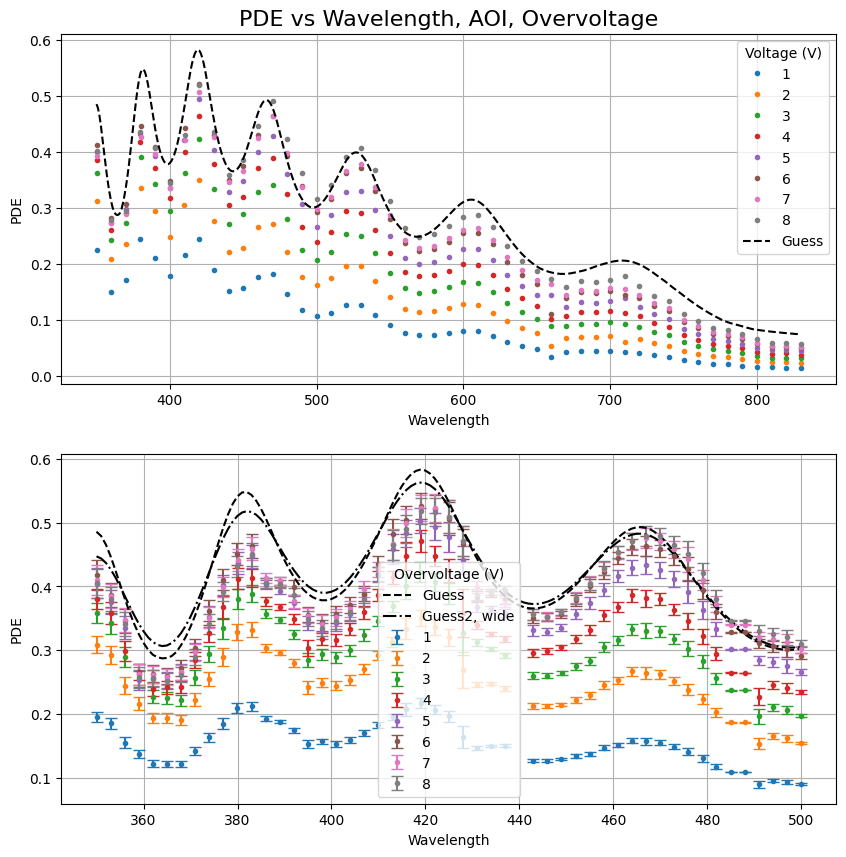

Angles: [1 2 3 4 5 6 7 8]
voltages: [1 2 3 4 5 6 7 8]


In [4]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False, figsize = (10, 10))

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax1)

# xv4 = df[df['Overvoltage'] == 4]
for voltage in data_voltagesHR:
    dt1 = dfHR[(dfHR['Angle'] == 0) & (dfHR['Overvoltage'] == voltage)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)
# some guesses
xGuess = np.arange(df['Wavelength'].min(), df['Wavelength'].max(), 1)
test_Boring = {"FF": 0.8, "quantum": False, "smoothSigma": None, "dh":None}

test_Boring2 = {"FF": 0.8, "quantum": False, "smoothSigma": 10, "dh":None}

testPars = {"tOxide": 1358, "dp_star": 1, "Xpn": 0.3e3, "dw_star": 6e3, "pe": 0.95, "ph": 0.35}
yGuess = FFS.PDE_allArgs_wlen(wlen=xGuess, theta1=0, **testPars, **test_Boring)
ax1.plot(xGuess, yGuess, label = "Guess", color = "black", linestyle = "--")

xGuess2 = np.arange(dfHR['Wavelength'].min(), dfHR['Wavelength'].max(), 1)
yGuess2 = FFS.PDE_allArgs_wlen(wlen=xGuess2, theta1=0, **testPars, **test_Boring)
ax2.plot(xGuess2, yGuess2, label = "Guess", color = "black", linestyle = "--")


yGuess_3 = FFS.PDE_allArgs_wlen(wlen=xGuess2, theta1=0, **testPars, **test_Boring2)
ax2.plot(xGuess2, yGuess_3, label = "Guess2, wide", color = "black", linestyle = "-.")

print("difference:", np.sum(np.abs(yGuess2 - yGuess_3)))

ax1.legend(title = "Voltage (V)")
ax1.set_ylabel("PDE")

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
# ax2.set_xlim(380, 420)

ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
# plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

-- Lei paper fit - digitized --
Vc = 1.734 ± 0.078
[0.         0.49406433 0.73082086 0.85328407 0.9128245  0.95003745
 0.97143852 0.98487739 0.99615724]
[0.         0.49060937 0.73286661 0.85603239 0.92180364 0.95893616
 0.97829063 0.98915744 0.99379866 0.99623366]
-- Lei paper fit - ROOT data --
Vc = 1.516 ± 0.011


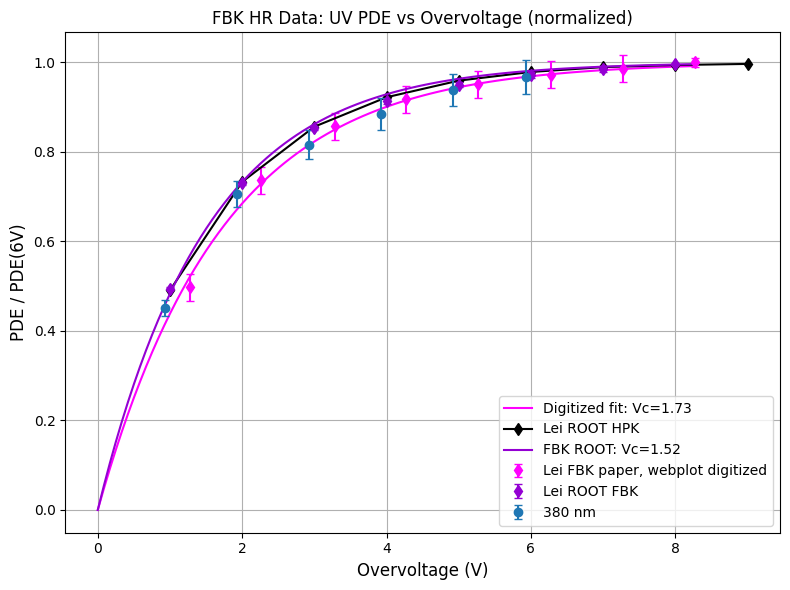

In [5]:
## Load and fit Pe data from Lei paper
from iminuit import Minuit
import uproot

fig, (ax_lei) = plt.subplots(1, 1, figsize=(8, 6))

c1 = ms.lxe2.col
c2 = ms.lxe.col

## Lei webplot digitized
xV_pe, yV_pe = np.loadtxt(os.path.join(VERA_DATA_PATH, "PE_vsV", "Pe_fbk_m60C_leiPaper.csv"), delimiter=",", skiprows=1, unpack=True)
mask = xV_pe > 0.5
xV_pe = xV_pe[mask]
yV_pe = yV_pe[mask]
yErr_pe = 0.03 * np.ones_like(yV_pe)  # 3% error on all points
yErr_pe[-1] = 0.01  # 3% error, 0.1% on highest V

chisq = lambda Vc: np.sum(((ME.Pcar_parametrized(xV_pe, Vc, 1.0) - yV_pe) / yErr_pe)**2)
m = Minuit(chisq, Vc=1.9); m.migrad()
print("-- Lei paper fit - digitized --")
print(f"Vc = {m.values['Vc']:.3f} ± {m.errors['Vc']:.3f}")

ax_lei.errorbar(xV_pe, yV_pe, yerr=yErr_pe, marker='d', color = c1, linestyle = "None", label='Lei FBK paper, webplot digitized', capsize=3)
xfit = np.linspace(0, max(xV_pe), 100)
ax_lei.plot(xfit, ME.Pcar_parametrized(xfit, m.values['Vc'], 1.0), color = c1, linestyle = "-", label=f"Digitized fit: Vc={m.values['Vc']:.2f}")

## Lei ROOT
fbkPath = "EH_Pair_PulseAnalysis_Output_FBK_R8_163K.root"
hpkPath = "lei_EH_Pair_PulseAnalysis_Output_HPK_R8_163K.root"
root160HPK = uproot.open(os.path.join(VERA_DATA_PATH, "PE_vsV", hpkPath))
plt.plot(root160HPK["Pe_Values"].member("fX")[1:], root160HPK["Pe_Values"].member("fY")[1:], marker='d', color = "k", linestyle = "-", label="Lei ROOT HPK")

root160 = uproot.open(os.path.join(VERA_DATA_PATH, "PE_vsV", fbkPath))

print(root160["Pe_Values"].member("fY"))
print(root160HPK["Pe_Values"].member("fY"))

gerr_160 = root160["Pe_Values"]
x160_root = gerr_160.member("fX")[1:]
y160_root = gerr_160.member("fY")[1:]
yerr160_root = gerr_160.member("fEY")[1:]

chisq_root = lambda Vc: np.sum(((ME.Pcar_parametrized(x160_root[:-1], Vc, 1.0) - y160_root[:-1]) / yerr160_root[:-1])**2)
m_root = Minuit(chisq_root, Vc=1.4); m_root.migrad()
print("-- Lei paper fit - ROOT data --")
print(f"Vc = {m_root.values['Vc']:.3f} ± {m_root.errors['Vc']:.3f}")

plt.errorbar(x160_root, y160_root, yerr=yerr160_root, color = c2, marker='d', linestyle = "None", label='Lei ROOT FBK', capsize=3)
plt.plot(xfit, ME.Pcar_parametrized(xfit, m_root.values['Vc'], 1.0), color = c2, linestyle = "-", label=f"FBK ROOT: Vc={m_root.values['Vc']:.2f}")

### plotting the data ###
# target_wlens = [350, 380, 400]
target_wlens = [380]
buffer = 1  # nm
vShift = 0.075
for wl_target in target_wlens:
    df_wl = dfHR[(dfHR['Wavelength'] >= wl_target - buffer) & (dfHR['Wavelength'] <= wl_target + buffer) & (dfHR['Angle'] == 0)]
    if len(df_wl) == 0:
        print(f"No data for {wl_target}nm")
        continue
    
    grouped = df_wl.groupby('Overvoltage').agg({'PDE': 'mean', 'PDE_error': 'mean'})
    voltages = grouped.index.values
    pde_vals = grouped['PDE'].values
    pde_errs = grouped['PDE_error'].values
    
    # Exclude 7V and 8V data
    mask = voltages < 7
    voltages = voltages[mask]
    pde_vals = pde_vals[mask]
    pde_errs = pde_errs[mask]
    
    # Normalize by 6V value
    idx_6v = np.argmin(np.abs(voltages - 6))
    normalizeTo = pde_vals[idx_6v]
    scale6V = ME.Pcar_parametrized(6-vShift, m.values['Vc'], 1.0)
    pde_norm = scale6V * pde_vals / normalizeTo
    pde_norm_err = scale6V * pde_errs / normalizeTo
    
    actual_wl = df_wl['Wavelength'].mean()
    ax_lei.errorbar(voltages-vShift, pde_norm, yerr=pde_norm_err, fmt='o', label=f'{actual_wl:.0f} nm', capsize=3)


###### formatting ######
ax_lei.set_title("Lei Paper Pe Data")

ax_lei.set_xlabel("Overvoltage (V)", fontsize=12)
ax_lei.set_ylabel("PDE / PDE(6V)", fontsize=12)
ax_lei.set_title("FBK HR Data: UV PDE vs Overvoltage (normalized)")
ax_lei.legend(loc = "lower right")
ax_lei.grid()

# ax_lei.hlines(0.88, xmin = 1, xmax = 6.2)

# ax_lei.set_xscale('log')
plt.tight_layout()
plt.show()

---
## Physics and Global Parameters
### input systematics

In [6]:
# these are bad
dh_franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dh_frantaRT = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))

MCFWHM = 4.5 # nm/mm

class systematics:
    def __init__(self):
        return

sys1 = systematics()

sys1.mScale = 1.32
sys1.mc_fwhm = MCFWHM * sys1.mScale # in nm
sys1.diodeError = 0.03
sys1.dh = dh_franta
sys1.temp = None
sys1.FF1 = 0.8
sys1.vOffset = 0.0 # this is subtracted

sys1.uvLim = 420

sys1.tOxide = 1358.1

peOutFileName = "FBK_Pcurves_default_franta_nested.csv"

## bounds and fixed (boring) parameters
fixedPars_UV_parametrized = {
                             "case": "B", 
                             "Temperature": sys1.temp, "quantum": False, "smoothSigma": sys1.mc_fwhm, "dh":sys1.dh,
                             "FF": sys1.FF1, "window": False}

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
----------------------------------------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/sili

{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


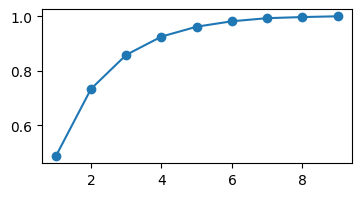

In [7]:
## Loading in Harry's PE data
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)
fHarry_interpPe = interp1d(df_pe["Overvoltage"], harryPe, kind='linear', fill_value="extrapolate")

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 2))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

[0.0090828  0.00982663 0.00777457 0.01433748 0.00615109 0.00929369
 0.0157151  0.01434825]
0.006151085970945968


array([0.10050373, 0.10777755, 0.13483694, 0.18935681, 0.27041635,
       0.37536116, 0.50249478, 0.65091935, 0.82015913])

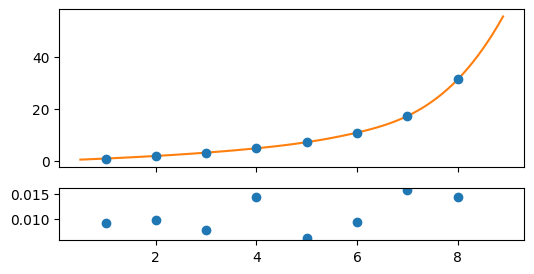

In [8]:
## loading in Harry's NCA error data 
file_path_nca = os.path.join(VERA_DATA_PATH, "NCA_errors/FBK_Q_sept24.csv")

xV_nca, yV_nca, yE_nca = np.loadtxt(file_path_nca, delimiter=",", unpack=True, skiprows=1, usecols=(0, 1, 2))

yV_nca_relative = yV_nca/min(yV_nca)
yE_nca_relative = yE_nca/yV_nca
print(yE_nca_relative)
finterp_nca = interp1d(xV_nca, yV_nca_relative, kind = "cubic", fill_value = "extrapolate")
finterp_ncaError = interp1d(xV_nca, yE_nca_relative, kind = "cubic", fill_value = "extrapolate")


fig, (ax1, ax2) = plt.subplots(2, 1, sharex=1, figsize = (6, 3), height_ratios=[3, 1])
ax1.errorbar(xV_nca, yV_nca_relative, yerr=10*yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
xfurther = np.arange(0.5, 9, 0.1)
ax1.plot(xfurther, finterp_nca(xfurther), label = "Interpolated")

ax2.plot(xV_nca, yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
# ax2.plot(xfurther, finterp_ncaError(xfurther), label = "Interpolated")

def getClosestNCAError(voltage):
    amin = np.argmin(np.abs(xV_nca - voltage))
    return yE_nca_relative[amin]

print(getClosestNCAError(4.6))

def quadErrors(value, valueErrors, *constantRelErrors):
    creArray = np.array(constantRelErrors)
    return value * np.sqrt((valueErrors/value)**2 + np.sum((creArray)**2))

xt = np.arange(0.1, 1, 0.1)
yt = xt**2
yerr = 0.1*yt

quadErrors(yt, yerr/yt, 1.0, 0.1)


---
## Building dataset object(s)

building 1d and 2d objects for single and nested fits

In [9]:
##-- Buiding global dataset from HR and LR data --##
angle_0A = data_angles[0]
print("picking angle:", angle_0A)

voltageTracker = data_voltages[:-2]
print("data voltages:", voltageTracker)

data_global_parametrized = []
data_global_nested = []

dataNested_UV = []
dataNested_IR = []

onlyData_global_LR = []
onlyData_global_HR = []

vHigh = max(voltageTracker)
data_UV_high = []
data_UV_all = []

Ndata = 0

for V in voltageTracker:
    
    # low res data
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    pde_lr = dfA_t1['PDE']
    pdeErrors_lr = dfA_t1['PDE_error']
    
    vToAnalyze = V - sys1.vOffset
    
    # total error on each PDE value
    totalPDEerror_lr = quadErrors(pde_lr, pdeErrors_lr, sys1.diodeError, getClosestNCAError(vToAnalyze))
    
    oneD_LRdict = {"wlen":dfA_t1['Wavelength'].values, "yVals": pde_lr, "yErrs": totalPDEerror_lr,
                   "theta1": angle_0A, "voltage": vToAnalyze}
    onlyData_global_LR.append(oneD_LRdict)
    data_global_parametrized.append(oneD_LRdict)
    
    # high res data
    dft1_HR = dfHR[(dfHR['Overvoltage'] == V) & (dfHR['Angle'] == angle_0A)]
    pde_hr = dft1_HR['PDE']
    pdeErrors_hr = dft1_HR['PDE_error']
    totalPDEerror_hr = quadErrors(pde_hr, pdeErrors_hr, sys1.diodeError, getClosestNCAError(vToAnalyze))
    
    oneD_HRdict = {"wlen":dft1_HR['Wavelength'].values, "yVals": pde_hr, "yErrs": totalPDEerror_hr, "theta1": angle_0A, "voltage": vToAnalyze}
    onlyData_global_HR.append(oneD_HRdict)
    data_global_parametrized.append(oneD_HRdict)
    
    Ndata += len(dfA_t1['Wavelength'].values) + len(dft1_HR['Wavelength'].values)
    
    #### UV and voltage datasets
    # print(dft1_HR['Wavelength'].values)
    uvMap_below400_hr = dft1_HR['Wavelength'].values < sys1.uvLim
    uvMap_below400_lr = dfA_t1['Wavelength'].values < sys1.uvLim
    
    oneD_lr_UV = {"wlen":dfA_t1['Wavelength'].values[uvMap_below400_lr], "yVals": pde_lr[uvMap_below400_lr], "yErrs": totalPDEerror_lr[uvMap_below400_lr], "theta1": angle_0A, "voltage": vToAnalyze}
    oneD_hr_UV = {"wlen":dft1_HR['Wavelength'].values[uvMap_below400_hr], "yVals": pde_hr[uvMap_below400_hr], "yErrs": totalPDEerror_hr[uvMap_below400_hr], "theta1": angle_0A, "voltage": vToAnalyze}
    data_UV_all.append(oneD_lr_UV)
    data_UV_all.append(oneD_hr_UV)
    if V == vHigh:
        tlr = oneD_lr_UV.copy()
        tlr.pop("voltage")
        thr = oneD_hr_UV.copy()
        thr.pop("voltage")
        data_UV_high.append(tlr)
        data_UV_high.append(thr)
    
    ############ for nested Pe, Ph fits ##############
    ## MUST REMOVE VOLTAGES FROM HERE
    odLR_copy = oneD_LRdict.copy()
    odHR_copy = oneD_HRdict.copy()
    odLR_copy.pop("voltage")
    odHR_copy.pop("voltage")
    dataDict_array = [odLR_copy, odHR_copy]
    # print(dataDict_array[0].keys())
    
    tempFixedPE = fHarry_interpPe(vToAnalyze)
    # print("V:", V, "guess pe:", tempFixedPE)
    
    floatNuisDict = {"pe": tempFixedPE, "ph": 0.15}
    floatBoundsNuisDict = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFullS = SS.OneNuisanceDataSet(oneDData=dataDict_array, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict, nuisanceFixed={})
    # ndof stuff
    # ndof = odFullS.CalcNDOF(xkey="wlen")
    # print("NDOF:", ndof)
    
    odFullS.extraV = vToAnalyze
    data_global_nested.append(odFullS)

# type(data_global_nested[0].oneDData);

# for single layer fits
SS.CheckDataSetKey_consistent(data_global_parametrized, True);
type(data_global_parametrized[0])
print(data_global_parametrized[0].keys())

picking angle: 0
data voltages: [1 2 3 4 5 6]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
dict_keys(['wlen', 'yVals', 'yErrs', 'theta1', 'voltage'])


---
### global 1: Single Level - Parametrized fit

no floating Psaturation or anything else like that

------ Case global1 setup ------
check all good: True
{'Ah': 1.0, 'case': 'B', 'Temperature': None, 'quantum': False, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1479dc110>, 'FF': 0.8, 'window': False, 'Ae': 1.0, 'vShift': 0}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


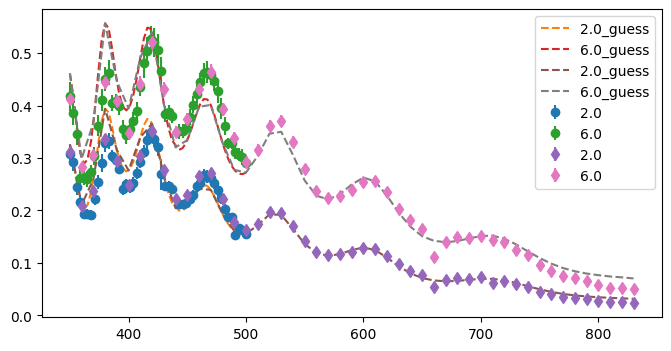

In [10]:
datFit = data_global_parametrized

# fitOpts = {"psatFloat": False, "fixVe":True}
# psatFloat = False

## bounds and fixed (boring) parameters
fixedPars_g1_parametrized = {"Ah":1.0, **fixedPars_UV_parametrized, "Ae":1.0, "vShift": 0}
# fixedPars_g1_parametrized.pop("FF")

# dh options are:
# None, dh_franta, dh_frantaRT
floatPars_g1_parametrized =  {"tOxide": 1355, "dp_star": 1.0, "Xpn": 0.5e3, "dw_star": 7e3, "Ve":1.73, "Vh":15}

# if fitOpts["psatFloat"]:
#   fixedPars_g1_parametrized.pop("Ae")
#   floatPars_g1_parametrized["Ae"] = 1.0

if (fixedPars_g1_parametrized["dh"] is not None) and fixedPars_g1_parametrized["Temperature"] is not None:
    if "franta" in fixedPars_g1_parametrized["dh"].mPathSi or "Franta" in fixedPars_g1_parametrized["dh"].mPathSi:
        print("Using franta and setting temperature. this is wrong. EXITING")
        sys.exit()
    
floatParBounds_global1 = {"Ae":(0.6, 1.1), "tOxide": (1345, 1365), "dp_star": (0.01, 10), "Xpn": (0.2e3, 1.4e3), "dw_star": (2e3, 20e3), "Ve": (0.5, 4), "Vh": (4, 30), "vShift": (-0.3, 0.3), "FF": (0.5, 1.0)}
floatParBounds_global1 = {k: floatParBounds_global1[k] for k in floatPars_g1_parametrized.keys()}

## make a wrapper function to include horizontal scaling in function
def FF_PDE_shifted(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, voltage, vShift, Ve, Vh, Ae, Ah, Temperature, smoothSigma, quantum, dh, window, case):
    return FFS.PDE_allArgs_wlen_parametrized(
        wlen=wlen, theta1=theta1, voltage=voltage - vShift, FF=FF,
        tOxide=tOxide, dp_star=dp_star, Xpn=Xpn, dw_star=dw_star, Vh=Vh, Ve=Ve, Ae=Ae, Ah=Ah, Temperature=Temperature, smoothSigma=smoothSigma, quantum=quantum, dh=dh, window=window, case=case
    )

x0_global1, x0_global1_names = SS.BuildX0(floatDict = floatPars_g1_parametrized, functionToFit=FF_PDE_shifted)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=FF_PDE_shifted)

print("------ Case global1 setup ------")
check = SS.CheckAllConditions_forResiduals(func=FF_PDE_shifted, dataObj=datFit, dFixed=fixedPars_g1_parametrized, dFloat=floatPars_g1_parametrized,
                                   dBounds=floatParBounds_global1, yNames=("yVals", "yErrs"), verbose=False)
print("check all good:", check)

############
## plot the guess at one high and one low voltage for HR data
plt.figure(figsize=(8, 4))
for d in [onlyData_global_HR[1], onlyData_global_HR[-1]]:
    plt.errorbar(d["wlen"], d["yVals"], yerr=d["yErrs"], label = f"{d['voltage']}", marker = "o", linestyle = "")
    
    yGuess = FF_PDE_shifted(wlen=d["wlen"], voltage = d['voltage'], theta1=angle_0A , **fixedPars_g1_parametrized, **floatPars_g1_parametrized)
    plt.plot(d["wlen"], yGuess, label = f"{d['voltage']}_guess", linestyle = "--")
    
for d in [onlyData_global_LR[1], onlyData_global_LR[-1]]:
    plt.errorbar(d["wlen"], d["yVals"], yerr=d["yErrs"], label = f"{d['voltage']}", marker = "d", linestyle = "")
    
    yGuess2 = FF_PDE_shifted(wlen=d["wlen"], voltage = d['voltage'], theta1=angle_0A , **fixedPars_g1_parametrized, **floatPars_g1_parametrized)
    plt.plot(d["wlen"], yGuess2, label = f"{d['voltage']}_guess", linestyle = "--")


print(fixedPars_g1_parametrized)
plt.legend()


In [11]:

print("------ Case global1 fit ------")
starTime = time.time()
result_global1 = iminuit.minimize(SS.GenericResiduals, x0=x0_global1, bounds = x0_global1_bounds, args=(fixedPars_g1_parametrized, datFit, FF_PDE_shifted), method='migrad',
                                #   tol = 10,
                                  options = {"display": False})

## calling it again
SS.GenericResiduals(x0=result_global1.x, dataObj=datFit, functionToFit=FF_PDE_shifted, fixedArgs_dict=fixedPars_g1_parametrized, verbose=False, yNames=("yVals", "yErrs"), )

print("\nDone fit!, time taken:", time.time()-starTime)
print("chi2 score-ish:", result_global1.fun)

resDict_global1 = SS.GetResDict(result_global1, x0_global1_names)
resDictErrors_global1 = SS.GetResErrorDict(result_global1, x0_global1_names)
print("values:", resDict_global1)
print("errors:", resDictErrors_global1)

------ Case global1 fit ------


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:791: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = migrad(ncall, self._tolerance)



Done fit!, time taken: 2.149616241455078
chi2 score-ish: 3293.2654567699437
values: {'tOxide': 1359.7458, 'dp_star': 1.2947, 'Xpn': 711.9914, 'dw_star': 4518.4362, 'Ve': 2.206, 'Vh': 13.313}
errors: {'tOxide': 0.2021, 'dp_star': 0.057, 'Xpn': 13.9008, 'dw_star': 84.9267, 'Ve': 0.0157, 'Vh': 0.3999}


In [12]:
print(result_global1)

  message: Optimization terminated successfully.
  success: True
      fun: 3293.2654567699437
        x: [ 1.360e+03  1.295e+00  7.120e+02  4.518e+03  2.206e+00
             1.331e+01]
 hess_inv: ┌────┬─────────────────────────────────────────────────────────────┐
           │    │        x0        x1        x2        x3        x4        x5 │
           ├────┼─────────────────────────────────────────────────────────────┤
           │ x0 │    0.0408    0.0009      0.02      0.55   0.02e-3      0.00 │
           │ x1 │    0.0009   0.00325   -0.3925   -1.4426  -0.58e-3   -0.0081 │
           │ x2 │      0.02   -0.3925       193    0.97e3 173.96e-3      5.09 │
           │ x3 │      0.55   -1.4426    0.97e3  7.21e+03 643.70e-3     32.81 │
           │ x4 │   0.02e-3  -0.58e-3 173.96e-3 643.70e-3  0.000247   3.61e-3 │
           │ x5 │      0.00   -0.0081      5.09     32.81   3.61e-3      0.16 │
           └────┴─────────────────────────────────────────────────────────────┘
     nfev: 241

6
NDOF: 588
reduced chi2: 5.6007915931461625


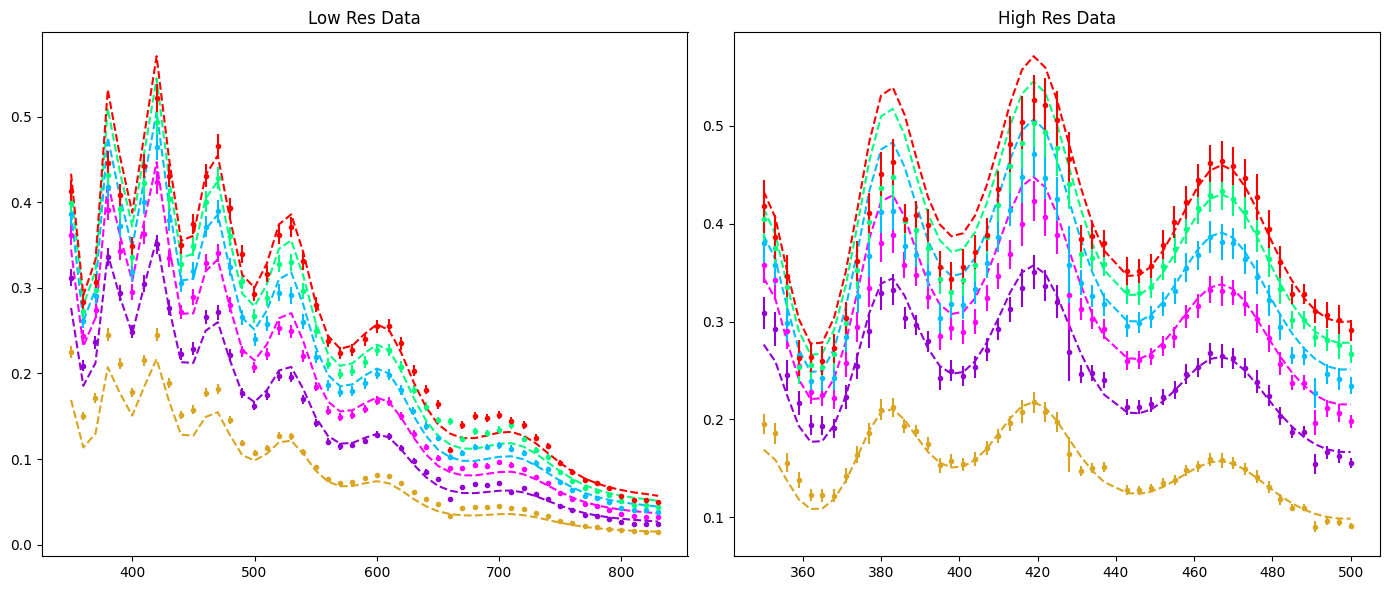

In [13]:

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=False, figsize = (14, 6)) 
ndofParam = - len(result_global1.x)
print(len(result_global1.x))

for dat in onlyData_global_HR:
    
    col = ms.GetNextColor()
    
    xVals = dat["wlen"]
    v = dat["voltage"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    ndofParam += len(xVals)
    
    ax2.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
    
    # yGuess = FFS.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v-0.2, **floatPars_g1_parametrized, **fixedPars_g1_parametrized)
    # ax2.plot(xVals, yGuess, color = col, linestyle = "--")
    
    ## fit
    yFit = FF_PDE_shifted(wlen=xVals, theta1=angle_0A, voltage = v, **resDict_global1, **fixedPars_g1_parametrized)
    ax2.plot(xVals, yFit, color = col, linestyle = "--")
    
for dat in onlyData_global_LR:
    
    col = ms.GetNextColor()
    
    xVals = dat["wlen"]
    v = dat["voltage"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    ndofParam += len(xVals)

    
    ax1.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
    
    # yGuess = FFS.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v, **floatPars_g1_parametrized, **fixedPars_g1_parametrized)
    # ax1.plot(xVals, yGuess, color = col, linestyle = "--")
    
    ## fit
    yFit = FF_PDE_shifted(wlen=xVals, theta1=angle_0A, voltage = v, **resDict_global1, **fixedPars_g1_parametrized)
    ax1.plot(xVals, yFit, color = col, linestyle = "--")

print("NDOF:", ndofParam)
print("reduced chi2:", result_global1.fun/ndofParam)

ax1.set_title("Low Res Data")
ax2.set_title("High Res Data" )

plt.tight_layout()

---
## Plotting Final fit results

------ Parametrized Fit Results ------
Fixed inputs: {'Ah': 1.0, 'case': 'B', 'Temperature': None, 'quantum': False, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1479dc110>, 'FF': 0.8, 'window': False, 'Ae': 1.0, 'vShift': 0}
data voltage offset: 0.0

Fit results: {'tOxide': 1359.7458, 'dp_star': 1.2947, 'Xpn': 711.9914, 'dw_star': 4518.4362, 'Ve': 2.206, 'Vh': 13.313}
Errors: {'tOxide': 0.2021, 'dp_star': 0.057, 'Xpn': 13.9008, 'dw_star': 84.9267, 'Ve': 0.0157, 'Vh': 0.3999}
Total chi2: 3293.27
Reduced chi2: 5.601


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_89991/3703605108.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


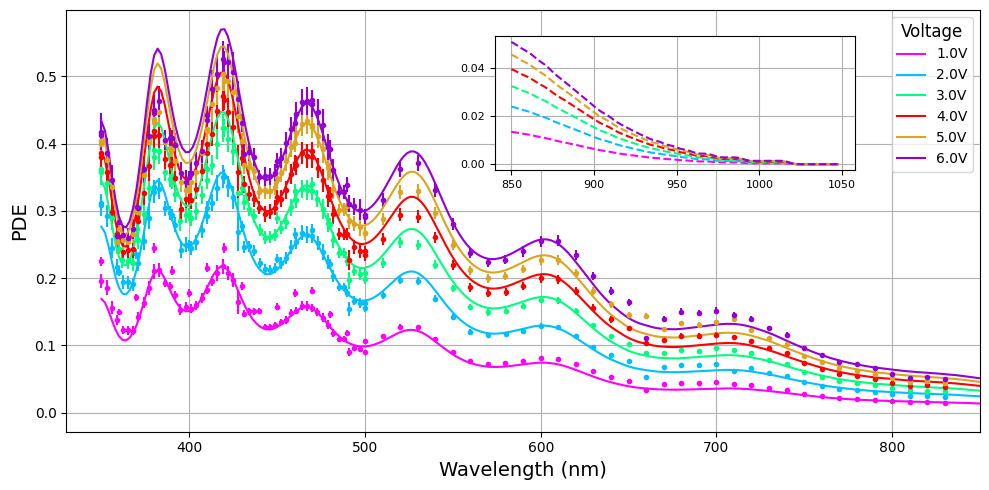

In [14]:
## Summary of parametrized fit
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

print("------ Parametrized Fit Results ------")
print("Fixed inputs:", fixedPars_g1_parametrized)
print("data voltage offset:", sys1.vOffset)
print("\nFit results:", resDict_global1)
print("Errors:", resDictErrors_global1)
print(f"Total chi2: {result_global1.fun:.2f}")
print(f"Reduced chi2: {result_global1.fun/ndofParam:.3f}")

## Plot final results
ms.ResetColorCycle()
ms.GetNextColor()
ms.GetNextColor()
fig, ax1 = plt.subplots(figsize=(10, 5))

spot = (570, 0.35, 205, 0.2)  # (x0, y0, width, height) in axes coordinates
axins = inset_axes(ax1, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax1.transData)

for dat in onlyData_global_LR + onlyData_global_HR:
    col = ms.GetNextColor()
    xVals, yVals, yErrs, v = dat["wlen"], dat["yVals"], dat["yErrs"], dat["voltage"]
    ax1.errorbar(xVals, yVals, yErrs, linestyle="", marker=".", color=col)

ms.ResetColorCycle()
ms.GetNextColor()
ms.GetNextColor()
for v in [d["voltage"] for d in onlyData_global_LR]:
    col = ms.GetNextColor()
    xvalFit = np.arange(350, 1050, 2)
    yFit = FF_PDE_shifted(wlen=xvalFit, theta1=angle_0A, voltage=v, **resDict_global1, **fixedPars_g1_parametrized)
    ax1.plot(xvalFit, yFit, linestyle="-", color=col, label=f"{v:.1f}V")
    
    insetLim = 850
    redMap = xvalFit >= insetLim
    axins.plot(xvalFit[redMap], yFit[redMap], linestyle="--", color=col)

axins.tick_params(labelsize=8)
axins.set_xticks(np.arange(insetLim, max(xvalFit)+50, 50))
axins.set_yticks(np.arange(0.0, 0.06, 0.02))
axins.grid()

ax1.set_xlim(330, 850)
ax1.grid()

ax1.set_ylabel("PDE", fontsize=14)
ax1.set_xlabel("Wavelength (nm)", fontsize=14)
ax1.legend(title="Voltage", fontsize=10, loc='upper right', title_fontsize='12')
plt.tight_layout()